<a href="https://colab.research.google.com/github/naylanara89/pm-turi4-clustering/blob/main/Clustering_dengan_K_Means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Menyiapkan data & scaling**

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 1. Definisikan DataFrame langsung di cell ini agar tidak perlu bolak-balik cell
data = {
    'usia': [25, 34, 45, 22, 35, 52, 23, 40, 60, 48],
    'pendapatan': [15, 25, 45, 18, 30, 55, 22, 41, 70, 50],
    'skor_belanja': [39, 81, 6, 77, 40, 14, 76, 25, 12, 19]
}
df = pd.DataFrame(data)

# 2. Lakukan scaling data (pastikan df sudah ada di atas baris ini)
X_scaled = StandardScaler().fit_transform(df)

# Tampilkan hasil scaling untuk memastikan berhasil
print(X_scaled)

[[-1.09177877 -1.2922209   0.00362335]
 [-0.35849452 -0.70750556  1.52543241]
 [ 0.53774178  0.46192512 -1.19208376]
 [-1.33620685 -1.1168063   1.38049821]
 [-0.27701849 -0.41514789  0.0398569 ]
 [ 1.10807398  1.04664046 -0.90221537]
 [-1.25473082 -0.88292017  1.34426466]
 [ 0.13036164  0.22803898 -0.50364633]
 [ 1.7598822   1.92371347 -0.97468247]
 [ 0.78216986  0.75428279 -0.72104762]]


### **Metode Elbow menentukan K**

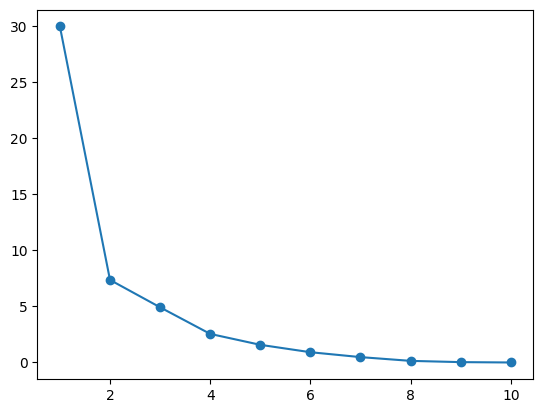

In [11]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()

### **Menjalankan K-Means (K=3)**

In [15]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())

cluster
1    5
0    3
2    2
Name: count, dtype: int64


### **Evaluasi silhouette score**

In [16]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))

0.4547238213629964


### **Interpretasi: profil rata-rata tiap cluster**

In [17]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil

         usia  pendapatan  skor_belanja
cluster                                
0        26.3        21.7          78.0
1        49.0        52.2          15.2
2        30.0        22.5          39.5


### **Perbandingan Silhouette Score ($K=5$ vs $K=3$) dan Tanpa ScalingPython**

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# --- NOMOR 6: K-Means dengan K=5 vs K=3 (Menggunakan data ber-scaling) ---
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_3 = kmeans_3.fit_predict(X_scaled)
score_3 = silhouette_score(X_scaled, labels_3)

kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_5 = kmeans_5.fit_predict(X_scaled)
score_5 = silhouette_score(X_scaled, labels_5)

print(f"Silhouette Score (K=3 dengan scaling): {score_3:.4f}")
print(f"Silhouette Score (K=5 dengan scaling): {score_5:.4f}")

# --- NOMOR 7: K-Means TANPA scaling (K=3) ---
kmeans_noscale = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_noscale = kmeans_noscale.fit_predict(df)
score_noscale = silhouette_score(df, labels_noscale)

print(f"Silhouette Score (K=3 TANPA scaling): {score_noscale:.4f}")

Silhouette Score (K=3 dengan scaling): 0.4547
Silhouette Score (K=5 dengan scaling): 0.3246
Silhouette Score (K=3 TANPA scaling): 0.5815


### **Scatter Plot Cluster (Fitur Usia vs Skor Belanja)**

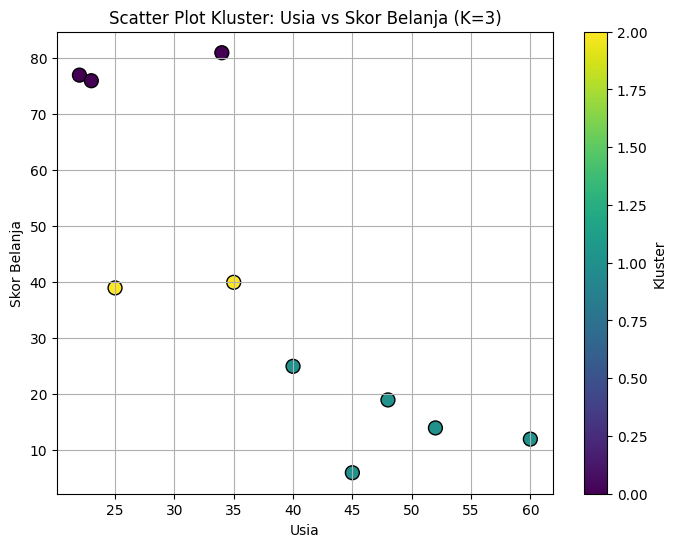

In [19]:
import matplotlib.pyplot as plt

# Memasukkan hasil kluster optimal (K=3 dengan scaling) ke dalam DataFrame
kmeans_opt = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans_opt.fit_predict(X_scaled)

# Membuat scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis', s=100, edgecolor='k')
plt.title('Scatter Plot Kluster: Usia vs Skor Belanja (K=3)')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.grid(True)
plt.colorbar(label='Kluster')
plt.show()

E. Refleksi

9. Bagaimana K-Means menemukan kelompok tanpa label?K-Means bekerja secara unsupervised dengan menginisialisasi titik pusat kluster (centroid) secara acak, lalu mengelompokkan setiap data ke centroid terdekat berdasarkan jarak (misalnya jarak Euclidean). Proses ini diulang secara iteratif hingga posisi centroid stabil dan tidak berubah lagi.

10. Mengapa metode Elbow menunjukkan siku di $K=3$ pada data ini?Karena pada titik $K=3$, penurunan nilai inertia (jumlah kuadrat jarak data ke centroid-nya) mulai melambat secara signifikan membentuk sudut siku. Penambahan jumlah kluster setelah angka 3 tidak memberikan informasi atau pengurangan error yang berarti bagi model.

11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?Scaling (seperti StandardScaler) penting untuk menyamakan rentang skala antar fitur. Jika dilewatkan, fitur dengan rentang nilai yang besar (misalnya pendapatan) akan mendominasi perhitungan jarak secara mutlak dibandingkan fitur dengan rentang kecil (misalnya usia), sehingga hasil kluster menjadi bias dan tidak akurat.